# Famílias avançadas e ajuste de hiperparâmetros

Além do híbrido residual `ŷ = b + α·r̂`, a busca pode testar três estruturas:

| Família | Estratégia | Ideia |
|---|---|---|
| `residual` | `residual_multistage` | correção da correção: cada estágio aprende o erro do modelo anterior (até 3) |
| `decomposition` | `decomposition` | `y = suave + volátil`; a base prevê a parte suave e um corretor a volátil. `ma`: média móvel **causal** com janela pela curtose; `stl`: só na variante A |
| `combination` | `fixed_combination` | média ponderada de duas bases; pesos iguais ou pelo inverso do erro fora da amostra no treino |

Todas obedecem às mesmas regras de causalidade: nada depois da origem entra no ajuste, nas janelas ou nos pesos. A seleção incremental trata cada uma como mais uma família: só entra se ganhar do campeão atual pela regra do protocolo.

No fim, `tune_model` ajusta os hiperparâmetros de uma base **só em `V_search`**.

In [1]:
import autohybts

print("AutoHybTS", autohybts.__version__)

AutoHybTS 0.0.1


## 1. Experimento

In [2]:
from autohybts import AutoHybridExperiment
from autohybts.datasets import get_data

y = get_data("synthetic_daily", n=500)
exp = AutoHybridExperiment(
    fh=14,
    session_id=42,
    fold=3,
    base_models=["naive", "seasonal_naive", "linear", "knn"],
    correctors=["linear"],
    residual_windows=[7],
    alphas=[1.0],
).fit(y)

## 2. Montar cada estrutura à mão

Cada chamada avalia a estrutura em todas as origens (`V_search` e `V_select`).

In [3]:
staged = exp.create_hybrid("seasonal_naive", "linear", extra_stages=["linear"])
decomposition = exp.create_decomposition("linear", "linear", method="ma")
combination = exp.create_combination(["seasonal_naive", "linear"], weights="inverse_mse")

for result in (staged, decomposition, combination):
    print(f"{result.metrics['MASE']:.3f}  {result.candidate.label}")

1.467  seasonal_naive + linear + linear [w=7, alpha=1.0, historical_oof_1step]
1.063  ma(curtose): linear(lags=7) | linear [w=7]
1.263  combinação[seasonal_naive(season_length=7) | linear(lags=7); inverse_mse]


Os diagnósticos de cada origem mostram o que foi aprendido só com o treino: a janela da média móvel escolhida pela curtose e os pesos da combinação.

In [4]:
import pandas as pd

pd.DataFrame(
    {
        "ma_window": [t.diagnostics.get("ma_window") for t in decomposition.evaluation.trials],
        "peso_seasonal_naive": [
            t.diagnostics.get("weight_0") for t in combination.evaluation.trials
        ],
        "peso_linear": [t.diagnostics.get("weight_1") for t in combination.evaluation.trials],
    },
    index=[t.fold_id for t in decomposition.evaluation.trials],
)

,ma_window,peso_seasonal_naive,peso_linear
search-0,199.0,0.303660,0.696340
search-1,205.0,0.294359,0.705641
search-2,213.0,0.287108,0.712892
select-0,220.0,0.281610,0.718390
select-1,227.0,0.284224,0.715776
select-2,233.0,0.272862,0.727138


## 3. Busca com todas as famílias

`include` escolhe as famílias. Estágios extras entram no refinamento S3; decomposições e combinações numa etapa S4, com o orçamento que sobrar (ao menos uma candidata por família).

In [5]:
result = exp.compare_models(
    include=("standalone", "residual", "multistage", "decomposition", "combination")
)
result.best

CandidateSpec(family='residual', strategy='residual_additive', base=ModelSpec(name='linear', params_json='{"lags":7}'), corrector=ModelSpec(name='linear', params_json='{}'), window_size=7, alpha=1.0, residual_source='historical_oof_1step', variant='A', members=(), options_json='{}', candidate_id='b678627c69f0bc5eb419617a2119103a8a5340ac96c0551898c62a1d76dc0179')

In [6]:
ledger = result.search.ledger_frame()
ledger.groupby(["stage", "strategy", "status"]).size()

stage  strategy             status            
S0     standalone           EVALUATED             4
S2     residual_additive    EVALUATED             4
S3     residual_additive    EVALUATED             2
                            SKIPPED_CAPABILITY    2
       residual_multistage  EVALUATED             2
S4     decomposition        EVALUATED             8
       fixed_combination    EVALUATED             2
dtype: int64

Decisões da cadeia incremental, família por família:

In [7]:
result.decisions[["family", "champion_before", "challenger", "accepted", "median_gain", "win_rate"]]

,family,champion_before,challenger,accepted,median_gain,win_rate
0,statistical,knn,seasonal_naive,True,0.142373,1.000000
1,linear,seasonal_naive,linear,True,0.186763,1.000000
2,kernel,linear,knn,False,-0.433787,0.000000
3,residual,linear,linear-linear,True,0.048048,0.666667
4,decomposition,linear-linear,ma(seasonal_naive-linear),False,-0.157533,0.333333
5,combination,linear-linear,"comb(knn,linear)",False,-0.307422,0.333333


## 4. Comparar as estratégias de montar o sistema

Cada candidata avaliada na busca vira um ponto: erro em `V_search` contra custo (ou complexidade, o número de modelos ajustados). A **fronteira de Pareto** liga as candidatas que nenhuma outra supera nos dois eixos: mostra o que cada passo de complexidade comprou. É relatório; a escolha do campeão continua sendo a regra do protocolo em `V_select`.

In [8]:
result.strategies

,candidates,best_score,median_score,mean_cost_seconds,best_model
strategy,,,,,
standalone,4,0.997024,1.255176,0.035066,knn
decomposition,8,1.018149,1.166869,0.452828,ma(seasonal_naive-linear)
fixed_combination,2,1.021385,1.095111,0.876087,"comb(knn,linear)"
residual_additive,6,1.197349,2.158421,0.429959,linear-linear
residual_multistage,2,1.228918,1.270350,18.352081,linear-linear-linear


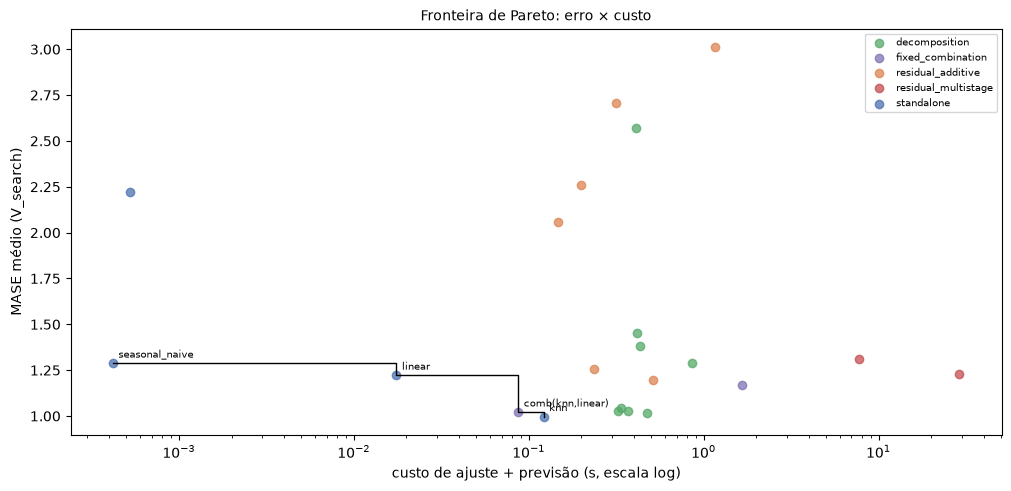

In [9]:
result.plot("pareto")

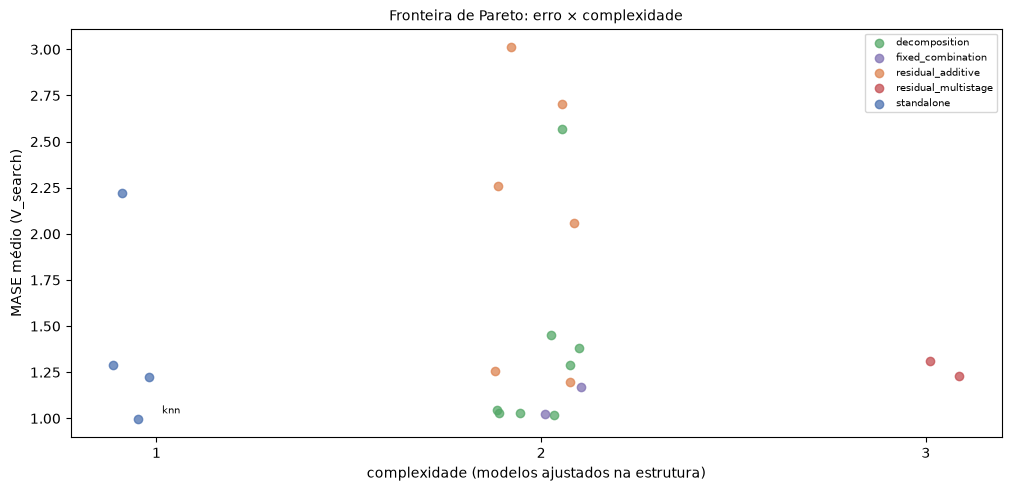

In [10]:
result.plot("pareto", x="complexity")

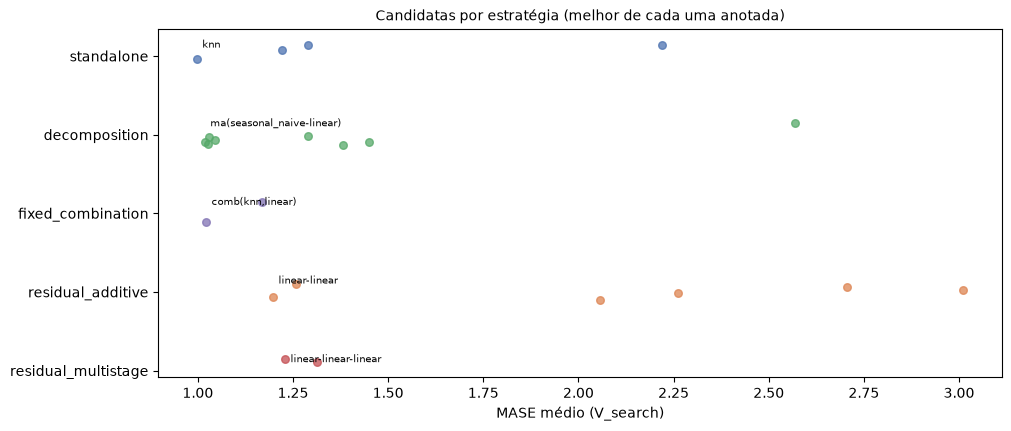

In [11]:
result.plot("strategies")

In [12]:
table = result.strategy_table()
table[table["pareto_cost"]][["name", "strategy", "score", "cost_seconds", "complexity"]]

,name,strategy,score,cost_seconds,complexity
0,knn,standalone,0.997024,0.121794,1
2,"comb(knn,linear)",fixed_combination,1.021385,0.087130,2
8,linear,standalone,1.222285,0.017522,1
11,seasonal_naive,standalone,1.288067,0.000420,1


## 5. Ajuste de hiperparâmetros

`tune_model` sorteia configurações da base (Optuna/TPE se o extra `optuna` estiver instalado; senão busca aleatória com semente) e pontua cada uma só em `V_search`. A configuração original é a tentativa 0, então o resultado nunca é pior que ela nessa camada. O `V_select` do modelo ajustado não foi visto pelo ajuste: compare nele.

In [13]:
tuned, tuner = exp.tune_model("knn", n_trials=15, return_tuner=True)
print(
    tuner.sampler,
    "| melhor:",
    tuner.best.label,
    "| ganho em V_search:",
    round(tuner.improvement, 3),
)
tuner.trials.sort_values("score").head()

optuna | melhor: knn(estimator_params={'n_neighbors': 4}, lags=9) | ganho em V_search: 0.07


,candidate_id,label,score,coverage,lags,estimator_params.n_neighbors
trial,,,,,,
9,f13455bf5d4c7c2fe3848bc69fda2d605c31ec84a72a04...,"knn(estimator_params={'n_neighbors': 4}, lags=9)",0.927339,1.0,9,4.0
12,b2507bfe6a5a5139cee8592ba25adbae126ecdfdb50935...,"knn(estimator_params={'n_neighbors': 16}, lags...",0.945013,1.0,28,16.0
14,825b4918ea827459fa3f70c23a4a2b24ae5cf89e3aa220...,"knn(estimator_params={'n_neighbors': 19}, lags...",0.981068,1.0,26,19.0
0,70ad174e1cc49eb256646399fb3e4b7d9df82f14f2978d...,knn(lags=7),0.997024,1.0,7,NaN
4,d3d11c72bb17bcf92dff9a1ebe27c65a49485371e83a56...,"knn(estimator_params={'n_neighbors': 14}, lags...",1.003079,1.0,20,14.0


In [14]:
original = exp.create_model("knn", lags=7)
pd.DataFrame(
    {
        "original": original.evaluation.to_frame().groupby("layer")["MASE"].mean(),
        "ajustado": tuned.evaluation.to_frame().groupby("layer")["MASE"].mean(),
    }
)

,original,ajustado
layer,,
search,0.997024,0.927339
select,1.826936,1.864958


Espaço próprio: `(mínimo, máximo)` para intervalos, lista para opções, nomes com ponto para parâmetros do estimador.

In [15]:
exp.tune_model(
    "svm",
    n_trials=6,
    search_space={
        "lags": (7, 21),
        "estimator_params.C": (0.1, 10.0),
        "estimator_params.epsilon": [0.01, 0.1],
    },
)

ModelResult('svm(lags=7)')